# Notebook 1 — Segmentacion Inteligente de MP3

Escanea recursivamente el directorio del dataset de entrenamiento, segmenta cada MP3 en fragmentos de 10 s
cortando en silencios naturales y guarda cada fragmento como `.wav` en
`C:\temporales\segmentos\`.

Al finalizar genera `C:\temporales\metadata.csv`.

**Soporta archivos de cualquier duración** (p.ej. grabaciones de 20 h):
el audio se procesa en bloques de 10 minutos sin cargarlo completo en RAM.
La RAM utilizada se limita al **80 %** de la disponible y el número de
procesos paralelos se ajusta automáticamente.

**Ejecutar las celdas de arriba hacia abajo en orden.**



In [10]:
# ============================================================
# CELDA 1 - CONFIGURACION + IMPORTS CRITICOS
# Ejecutar esta celda SIEMPRE primero tras iniciar el kernel
# ============================================================

import os
import sys
import io
import json
import hashlib
import warnings
import subprocess
import threading
from pathlib import Path
import pandas as pd

warnings.filterwarnings('ignore')

# -- Apuntar pydub directamente a ffmpeg (no depende del PATH del sistema) --
FFMPEG_BIN = r"C:\Users\sukho\AppData\Local\Microsoft\WinGet\Packages\Gyan.FFmpeg_Microsoft.Winget.Source_8wekyb3d8bbwe\ffmpeg-8.1.2-full_build\bin"

if FFMPEG_BIN not in os.environ.get('PATH', ''):
    os.environ['PATH'] = FFMPEG_BIN + os.pathsep + os.environ.get('PATH', '')

from pydub import AudioSegment
AudioSegment.converter = str(Path(FFMPEG_BIN) / 'ffmpeg.exe')
AudioSegment.ffmpeg    = str(Path(FFMPEG_BIN) / 'ffmpeg.exe')
AudioSegment.ffprobe   = str(Path(FFMPEG_BIN) / 'ffprobe.exe')

result = subprocess.run([AudioSegment.converter, '-version'],
                        capture_output=True, text=True)
if result.returncode == 0:
    print(f'ffmpeg OK: {AudioSegment.converter}')
else:
    print('ERROR: ffmpeg no encontrado. Revisar FFMPEG_BIN')

# -- Rutas --------------------------------------------------
SOURCE_DIR    = r"C:\Compartida Fast\CintasTestigo"
TEMP_DIR      = r"C:\temporales\segmentos"
METADATA_PATH = r"C:\temporales\metadata.csv"

# -- Parametros de segmentacion ----------------------------
MIN_SEGMENT_MS  = 10_000   # largo minimo de segmento (ms)
MAX_SEGMENT_MS  = 10_000   # largo maximo de segmento (ms: 10 segundos)
MIN_SILENCE_MS  = 400      # silencio minimo para cortar (ms)
SILENCE_DB_DIFF = 16       # umbral = dBFS_chunk - este valor
SAMPLE_RATE     = 32_000   # Hz de los WAVs de salida
RESUME          = True     # True = saltar archivos ya procesados

# -- Parametros de chunking (soporte para archivos de cualquier duracion) --
#    El audio se lee en bloques de CHUNK_S segundos via ffmpeg pipe,
#    sin cargar el archivo completo en RAM.
#    OVERLAP_S debe ser >= MAX_SEGMENT_MS / 1000 para no perder
#    segmentos que caen justo en el limite entre dos chunks.
CHUNK_S   = 600   # duracion de cada chunk en segundos (10 min)
OVERLAP_S = 10    # solapamiento al final de cada chunk en segundos (10 s)

os.makedirs(TEMP_DIR, exist_ok=True)
print('Configuracion lista')
print(f'  Source  : {SOURCE_DIR}')
print(f'  Temp    : {TEMP_DIR}')
print(f'  Metadata: {METADATA_PATH}')
print(f'  Chunk   : {CHUNK_S} s + {OVERLAP_S} s overlap')


ffmpeg OK: C:\Users\sukho\AppData\Local\Microsoft\WinGet\Packages\Gyan.FFmpeg_Microsoft.Winget.Source_8wekyb3d8bbwe\ffmpeg-8.1.2-full_build\bin\ffmpeg.exe
Configuracion lista
  Source  : C:\Compartida Fast\CintasTestigo
  Temp    : C:\temporales\segmentos
  Metadata: C:\temporales\metadata.csv
  Chunk   : 600 s + 10 s overlap


In [11]:
# CELDA 2 - IMPORTS DE AUDIO
from pydub.silence import detect_nonsilent
from tqdm.notebook import tqdm

print('Librerias de audio cargadas')


Librerias de audio cargadas


In [12]:
# CELDA 3 — ESCANEAR TODOS LOS MP3 RECURSIVAMENTE
all_mp3s = sorted(Path(SOURCE_DIR).rglob("*.mp3"))
all_mp3s += sorted(Path(SOURCE_DIR).rglob("*.MP3"))
all_mp3s = list(set(all_mp3s))

print(f"Total archivos MP3 encontrados: {len(all_mp3s)}")
total_gb = sum(f.stat().st_size for f in all_mp3s) / (1024**3)
print(f"Tamano total: {total_gb:.2f} GB")


Total archivos MP3 encontrados: 275
Tamano total: 8.68 GB


In [13]:
# CELDA 4 — CARGAR PROGRESO ANTERIOR (modo RESUME)
csv_path = Path(METADATA_PATH)
if RESUME and csv_path.exists() and csv_path.stat().st_size > 0:
    try:
        existing_df = pd.read_csv(METADATA_PATH)
        already_processed = set(existing_df['archivo_origen'].unique())
        print(f"Retomando: {len(already_processed)} archivos ya procesados, "
              f"{len(existing_df)} segmentos en disco")
        existing_records = existing_df.to_dict('records')
    except Exception as e:
        print(f"Advertencia: no se pudo leer metadata.csv ({e}). Iniciando desde cero.")
        already_processed = set()
        existing_records = []
else:
    already_processed = set()
    existing_records = []
    if csv_path.exists() and csv_path.stat().st_size == 0:
        print("metadata.csv existe pero esta vacio — iniciando desde cero")
    else:
        print("Iniciando segmentacion desde cero")

pending_mp3s = [f for f in all_mp3s if str(f) not in already_processed]
print(f"Archivos pendientes: {len(pending_mp3s)}")


Iniciando segmentacion desde cero
Archivos pendientes: 275


In [14]:
# CELDA 5 — FUNCIONES Y HELPER WORKER DE SEGMENTACION
import sys
from pathlib import Path
CURRENT_DIR = str(Path.cwd())
if CURRENT_DIR not in sys.path:
    sys.path.append(CURRENT_DIR)

from _segmentacion_worker import (
    get_file_id,
    get_duration_ffprobe,
    extract_chunk_ffmpeg,
    build_segments_from_chunk,
    procesar_mp3_worker
)

print('Funciones de segmentación importadas correctamente desde _segmentacion_worker.py')


Funciones de segmentación importadas correctamente desde _segmentacion_worker.py


In [15]:
# CELDA 6 — CONCURRENCIA ADAPTATIVA BASADA EN CPU Y RAM (MULTIPROCESSING)
# ─────────────────────────────────────────────────────────────
# Usa psutil para medir la RAM libre y os.cpu_count() para
# determinar la cantidad óptima de procesos paralelos independientes.
# ─────────────────────────────────────────────────────────────
try:
    import psutil
except ImportError:
    import subprocess as _sp
    _sp.run(['pip', 'install', '-q', 'psutil'], check=True)
    import psutil

mem           = psutil.virtual_memory()
AVAILABLE_RAM = mem.available        # RAM libre ahora mismo
TARGET_RAM    = AVAILABLE_RAM * 0.80 # usar el 80 %

_bytes_per_sample  = 2
_overhead_factor   = 2.5
CHUNK_RAM_BYTES = (CHUNK_S + OVERLAP_S) * SAMPLE_RATE * _bytes_per_sample * _overhead_factor

MAX_RAM_PROCESSES = max(1, int(TARGET_RAM / CHUNK_RAM_BYTES))
NUM_PROCESSES     = max(1, min(os.cpu_count() or 4, MAX_RAM_PROCESSES))

print(f'RAM total         : {mem.total / 1e9:.1f} GB')
print(f'RAM disponible    : {AVAILABLE_RAM / 1e9:.1f} GB')
print(f'RAM objetivo 80 % : {TARGET_RAM / 1e9:.1f} GB')
print(f'RAM por chunk     : {CHUNK_RAM_BYTES / 1e6:.0f} MB'
      f'  ({CHUNK_S} s chunk + {OVERLAP_S} s overlap)')
print(f'Núcleos de CPU    : {os.cpu_count()}')
print(f'Procesos paralelos: {NUM_PROCESSES} (ProcessPoolExecutor)')


RAM total         : 34.1 GB
RAM disponible    : 7.3 GB
RAM objetivo 80 % : 5.8 GB
RAM por chunk     : 98 MB  (600 s chunk + 10 s overlap)
Núcleos de CPU    : 28
Procesos paralelos: 28 (ProcessPoolExecutor)


In [16]:
# CELDA 7 — PROCESAR TODOS LOS MP3 PENDIENTES EN PARALELO (PROCESS POOL)
#           Multiprocesamiento sin restricción de GIL de Python
from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm.notebook import tqdm
from _segmentacion_worker import procesar_mp3_worker

new_records = []
errors      = []

worker_tasks = [
    {
        'mp3_path'       : str(p),
        'temp_dir'       : TEMP_DIR,
        'ffmpeg_bin'     : FFMPEG_BIN,
        'min_segment_ms' : MIN_SEGMENT_MS,
        'max_segment_ms' : MAX_SEGMENT_MS,
        'min_silence_ms' : MIN_SILENCE_MS,
        'silence_db_diff': SILENCE_DB_DIFF,
        'sample_rate'    : SAMPLE_RATE,
        'chunk_s'        : CHUNK_S,
        'overlap_s'      : OVERLAP_S,
    }
    for p in pending_mp3s
]

with ProcessPoolExecutor(max_workers=NUM_PROCESSES) as executor:
    futures = {executor.submit(procesar_mp3_worker, task): task['mp3_path'] for task in worker_tasks}

    with tqdm(total=len(pending_mp3s), desc='Segmentando (Multi-core)', unit='archivo') as pbar:
        for future in as_completed(futures):
            recs, err = future.result()
            if err:
                errors.append(err)
            else:
                new_records.extend(recs)
            pbar.update(1)

# Guardado final (se genera metadata.csv únicamente al terminar todos los archivos)
all_records = existing_records + new_records
df = pd.DataFrame(all_records)
df.to_csv(METADATA_PATH, index=False)

print('Segmentación completa')
print(f'  Total segmentos   : {len(df):,}')
print(f'  Nuevos esta sesión: {len(new_records):,}')
print(f'  Errores           : {len(errors)}')
print(f'  Metadata guardada : {METADATA_PATH}')


Segmentando (Multi-core):   0%|          | 0/275 [00:00<?, ?archivo/s]

Segmentación completa
  Total segmentos   : 46,471
  Nuevos esta sesión: 46,471
  Errores           : 16
  Metadata guardada : C:\temporales\metadata.csv


In [17]:
# CELDA 7 — REPORTE DE ERRORES
if errors:
    err_df  = pd.DataFrame(errors)
    err_path = r"C:\temporales\errores_segmentacion.csv"
    err_df.to_csv(err_path, index=False)
    print(f"Se guardaron {len(errors)} errores en: {err_path}")
    print(err_df.head(10))
else:
    print("Sin errores")


Se guardaron 16 errores en: C:\temporales\errores_segmentacion.csv
                                             archivo            error
0  C:\Compartida Fast\CintasTestigo\20260720-0900...    Sin segmentos
1  C:\Compartida Fast\CintasTestigo\20260713-0900...  ffprobe error: 
2  C:\Compartida Fast\CintasTestigo\20260708-0900...    Sin segmentos
3  C:\Compartida Fast\CintasTestigo\20260727-0900...    Sin segmentos
4  C:\Compartida Fast\CintasTestigo\20260716-0900...    Sin segmentos
5  C:\Compartida Fast\CintasTestigo\20260710-0900...    Sin segmentos
6  C:\Compartida Fast\CintasTestigo\20260709-0900...  ffprobe error: 
7  C:\Compartida Fast\CintasTestigo\20260715-0900...    Sin segmentos
8  C:\Compartida Fast\CintasTestigo\20260729-0900...    Sin segmentos
9  C:\Compartida Fast\CintasTestigo\20260717-0900...    Sin segmentos


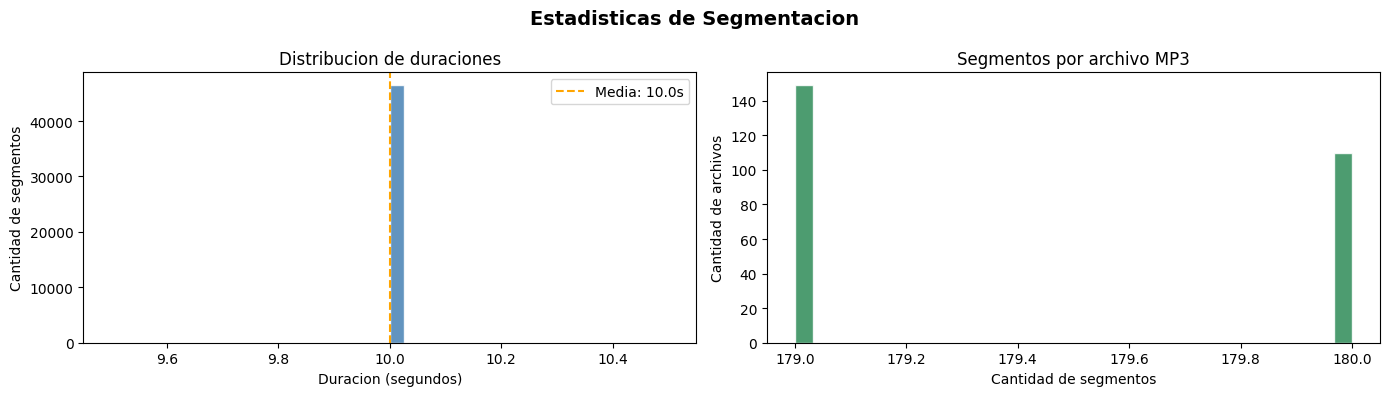

Segmentos totales : 46,471
Archivos MP3      : 259
Duracion promedio : 10.0 seg
Duracion total    : 129.1 horas de audio


In [18]:
# CELDA 8 — ESTADISTICAS DEL RESULTADO
# Puede ejecutarse sola para ver el estado actual del CSV
import matplotlib.pyplot as plt

if not Path(METADATA_PATH).exists():
    print(f"El archivo '{METADATA_PATH}' no existe todavia.")
    print("Ejecuta primero las celdas 3-6 para correr la segmentacion.")
else:
    df = pd.read_csv(METADATA_PATH)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle("Estadisticas de Segmentacion", fontsize=14, fontweight='bold')

    axes[0].hist(df['duracion_s'], bins=40, color='steelblue',
                 edgecolor='white', alpha=0.85)
    axes[0].set_title("Distribucion de duraciones")
    axes[0].set_xlabel("Duracion (segundos)")
    axes[0].set_ylabel("Cantidad de segmentos")
    axes[0].axvline(df['duracion_s'].mean(), color='orange', linestyle='--',
                   label=f"Media: {df['duracion_s'].mean():.1f}s")
    axes[0].legend()

    segs_por_archivo = df.groupby('archivo_origen').size()
    axes[1].hist(segs_por_archivo, bins=30, color='seagreen',
                 edgecolor='white', alpha=0.85)
    axes[1].set_title("Segmentos por archivo MP3")
    axes[1].set_xlabel("Cantidad de segmentos")
    axes[1].set_ylabel("Cantidad de archivos")

    plt.tight_layout()
    plt.show()

    print(f"Segmentos totales : {len(df):,}")
    print(f"Archivos MP3      : {df['archivo_origen'].nunique():,}")
    print(f"Duracion promedio : {df['duracion_s'].mean():.1f} seg")
    print(f"Duracion total    : {df['duracion_s'].sum() / 3600:.1f} horas de audio")
